**CS 4140 – Deep Learning · L05 · PyTorch in four ideas** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L05_pytorch/L05_pytorch_four_ideas.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L05_pytorch"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 5 · PyTorch: four ideas behind every model

**Tensors · Autograd · Modules · The training loop**, then a "Debug the AI" exercise.

You will often get PyTorch code from an AI assistant. The goal today is not to memorise the API but to be able to **read** that code,
**predict** what it does, and **test** that it does it.

| Section | Idea | Time |
|---|---|---|
| 1 | Tensors: boxes of numbers with a shape; one minibatch traced through a network | instant (first run downloads Fashion-MNIST, ~30 MB) |
| 2 | Autograd: the gradient three ways (by hand, by nudging, by `backward()`) | instant |
| 3 | Modules: a model is a function with knobs | instant |
| 4 | The training loop: five lines, forever | ~40 s, or load saved weights |
| 5 | Debug the AI: three silent bugs in a house-price model | ~5 s |
| 6 | Exercises | — |

Set `RUN_TRAINING = False` in class to load `fashion_mlp_sgd.pt` instead of training.

In [1]:
import time, math, warnings
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from matplotlib import font_manager

RUN_TRAINING = True       # False: load fashion_mlp_sgd.pt (saved by this notebook)
torch.manual_seed(0)
torch.set_num_threads(1)  # small models: one thread is fast enough and makes runs repeatable
FIG = Path('figs'); FIG.mkdir(exist_ok=True)

# where tensors will live: a GPU if there is one, otherwise the CPU (same code either way)
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device)

for fam in ['Century Schoolbook', 'TeX Gyre Schola', 'C059', 'DejaVu Serif']:
    if any(fam == f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = fam
        break
plt.rcParams.update({'font.size': 16, 'axes.spines.top': False, 'axes.spines.right': False})
NAVY, BLUE, RED, ORANGE, GREY, GREEN = '#000080', '#0070C0', '#E00000', '#E69F00', '#808080', '#2E7D32'

# Fashion-MNIST, as on Jan 15 (reuses a ./data folder if you already have one)
to_tensor = transforms.ToTensor()          # image -> tensor of shape (1, 28, 28) with values in [0, 1]
train_set = datasets.FashionMNIST('data', train=True, download=True, transform=to_tensor)
test_set = datasets.FashionMNIST('data', train=False, download=True, transform=to_tensor)
CLASSES = train_set.classes
print(len(train_set), 'training images,', len(test_set), 'test images, classes:', CLASSES)

PyTorch 2.14.1+cpu | device: cpu
60000 training images, 10000 test images, classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 1. Tensors: boxes of numbers with a shape

A tensor is a NumPy array that can also live on a GPU and remember how it was computed (section 2). Its most important property is its **shape**.

In [2]:
loss_like = torch.tensor(0.42)              # a scalar: shape ()
bias      = torch.zeros(128)                # a vector: shape (128,)
weights   = torch.randn(128, 784)           # a matrix: shape (128, 784)
photo     = torch.rand(3, 224, 224)         # one colour image: channels x height x width
for name, t in [('scalar', loss_like), ('vector', bias), ('matrix', weights), ('colour image', photo)]:
    print(f'{name:13s} shape {str(tuple(t.shape)):17s} dtype {t.dtype}   lives on {t.device}')

scalar        shape ()                dtype torch.float32   lives on cpu
vector        shape (128,)            dtype torch.float32   lives on cpu
matrix        shape (128, 784)        dtype torch.float32   lives on cpu
colour image  shape (3, 224, 224)     dtype torch.float32   lives on cpu


images x: (64, 1, 28, 28) torch.float32    labels y: (64,) torch.int64
first labels: ['Sneaker', 'Trouser', 'Coat', 'T-shirt/top', 'T-shirt/top', 'Bag']


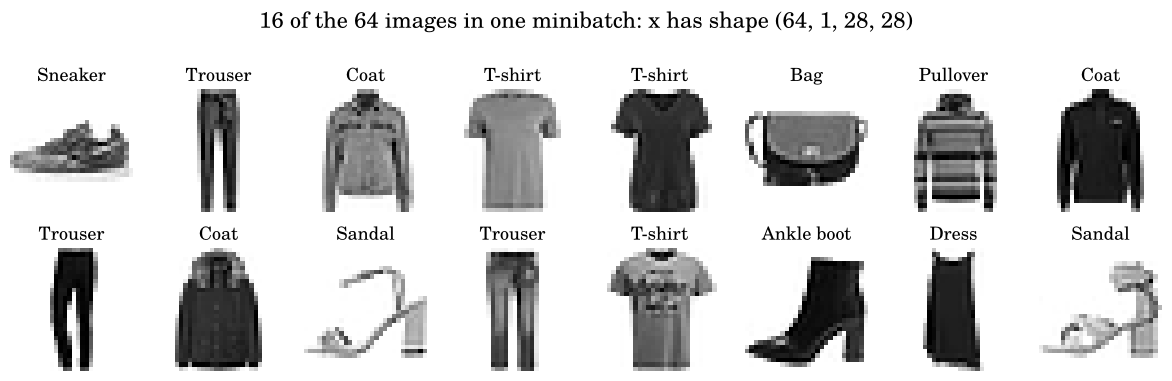

In [3]:
loader = DataLoader(train_set, batch_size=64, shuffle=True)
x, y = next(iter(loader))                   # ONE minibatch
print('images x:', tuple(x.shape), x.dtype, '   labels y:', tuple(y.shape), y.dtype)
print('first labels:', [CLASSES[i] for i in y[:6]])

fig, axes = plt.subplots(2, 8, figsize=(12, 4.1))
for ax, img, lab in zip(axes.ravel(), x, y):
    ax.imshow(img[0], cmap='gray_r'); ax.set_title(CLASSES[lab].split('/')[0], fontsize=13); ax.axis('off')
plt.suptitle('16 of the 64 images in one minibatch: x has shape (64, 1, 28, 28)', fontsize=16)
plt.tight_layout(); fig.savefig(FIG / 'minibatch.png', dpi=200, bbox_inches='tight'); plt.show()

**Trace the minibatch through the Jan 15 network.** The first number (the batch, 64) never changes; each layer changes only the last one.

In [4]:
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
h = x
print(f'{"input":28s} {tuple(h.shape)}')
for layer in model:
    h = layer(h)
    print(f'{str(layer):28s} {tuple(h.shape)}')
loss = nn.CrossEntropyLoss()(h, y)
print(f'{"CrossEntropyLoss(h, y)":28s} {tuple(loss.shape)}  = {loss.item():.3f}   (one number for the whole batch)')

input                        (64, 1, 28, 28)
Flatten(start_dim=1, end_dim=-1) (64, 784)
Linear(in_features=784, out_features=128, bias=True) (64, 128)
ReLU()                       (64, 128)
Linear(in_features=128, out_features=10, bias=True) (64, 10)
CrossEntropyLoss(h, y)       ()  = 2.337   (one number for the whole batch)


**Broadcasting.** When shapes differ, PyTorch stretches the smaller tensor if it can. That is how one bias vector is added to all 64 rows.
It is also how a silent bug happens: a column `(5, 1)` minus a row `(5,)` becomes a `(5, 5)` table. Section 5 has this bug in real code.

In [5]:
z = torch.randn(64, 128)
print('(64, 128) + (128,)  ->', tuple((z + bias).shape), '  good: the same bias for every example')

pred   = torch.tensor([[3.1], [2.4], [4.0], [1.9], [3.3]])   # model output: shape (5, 1)
target = torch.tensor([3.0, 2.5, 3.9, 2.0, 3.2])             # labels:       shape (5,)
diff = pred - target
print('(5, 1) - (5,)       ->', tuple(diff.shape), '  bad: every prediction minus every target')
print('mean squared error, wrong shapes:', round((diff ** 2).mean().item(), 3),
      '  right shapes:', round(((pred.squeeze(1) - target) ** 2).mean().item(), 3))

(64, 128) + (128,)  -> (64, 128)   good: the same bias for every example
(5, 1) - (5,)       -> (5, 5)   bad: every prediction minus every target
mean squared error, wrong shapes: 0.944   right shapes: 0.01


## 2. Autograd: the gradient three ways

A tiny model with one weight: prediction ŷ = w·x + b, loss J = (ŷ − y)², with x = 3, b = 1, target y = 10 and the current weight w = 2.
The **gradient** ∂J/∂w answers: *if I nudge w a little, how much does the loss change?*

In [6]:
x0, b0, y0, w0 = 3.0, 1.0, 10.0, 2.0
J = lambda w: (w * x0 + b0 - y0) ** 2

# 1) by hand (chain rule): dJ/dw = 2 (y_hat - y) * x
by_hand = 2 * (w0 * x0 + b0 - y0) * x0

# 2) by nudging: change w by a tiny eps and watch J
eps = 1e-3
by_nudge = (J(w0 + eps) - J(w0)) / eps

# 3) by autograd
w = torch.tensor(w0, requires_grad=True)     # "track everything that happens to w"
loss = (w * x0 + b0 - y0) ** 2               # forward: PyTorch records each step
loss.backward()                              # backward: the chain rule, automatically
print(f'J(2) = {J(w0):.3f},  J(2.001) = {J(w0 + eps):.6f}')
print(f'by hand: {by_hand:.3f}   by nudging: {by_nudge:.3f}   by autograd: {w.grad.item():.3f}')

J(2) = 9.000,  J(2.001) = 8.982009
by hand: -18.000   by nudging: -17.991   by autograd: -18.000


In [7]:
# PyTorch kept a record (the computational graph) of how loss was computed:
node, depth = loss.grad_fn, 0
while node is not None:
    print('   ' * depth + type(node).__name__)
    nxt = [f for f, _ in node.next_functions if f is not None and type(f).__name__ != 'AccumulateGrad']
    node, depth = (nxt[0] if nxt else None), depth + 1
print('(read bottom-up: multiply, add, subtract, square = the forward pass; backward walks it top-down)')

PowBackward0
   SubBackward0
      AddBackward0
         MulBackward0
(read bottom-up: multiply, add, subtract, square = the forward pass; backward walks it top-down)


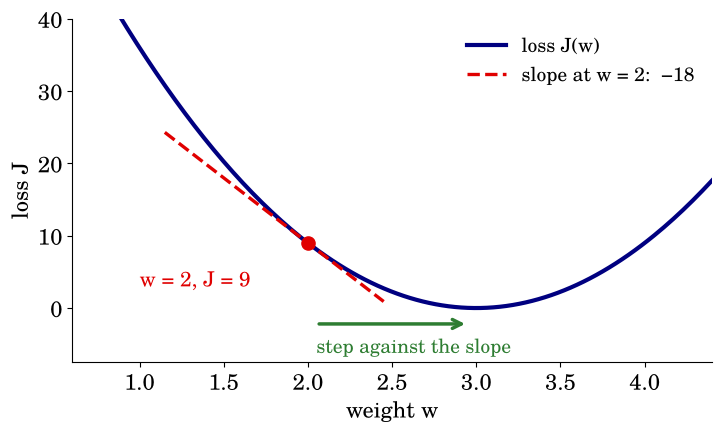

In [8]:
# The nudge test as a picture (used on slide 8)
ws = np.linspace(0.6, 4.4, 200)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(ws, J(ws), color=NAVY, lw=3, label='loss J(w)')
wt = np.linspace(1.15, 2.45, 50)
ax.plot(wt, J(w0) + by_hand * (wt - w0), '--', color=RED, lw=2.4, label='slope at w = 2:  −18')
ax.scatter([w0], [J(w0)], color=RED, s=90, zorder=5)
ax.annotate('w = 2, J = 9', (w0, J(w0)), xytext=(1.0, 3.0), fontsize=15, color=RED)
ax.annotate('', xy=(2.95, -2.2), xytext=(2.05, -2.2), arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5))
ax.text(2.05, -6.2, 'step against the slope', color=GREEN, fontsize=14)
ax.set_xlabel('weight w'); ax.set_ylabel('loss J'); ax.set_ylim(-7.5, 40); ax.set_xlim(0.6, 4.4)
ax.legend(frameon=False, loc='upper right', fontsize=14)
plt.tight_layout(); fig.savefig(FIG / 'nudge.png', dpi=200, bbox_inches='tight'); plt.show()

**Does autograd also agree for a real network?** Pick one weight of the Fashion-MNIST network, nudge it, and compare. (Double precision makes the nudge exact enough to compare four digits.)

In [9]:
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)).double()
xb, yb = x.double(), y
loss_fn = nn.CrossEntropyLoss()
net.zero_grad(); loss_fn(net(xb), yb).backward()
W1 = net[1].weight
i, j = 5, 400                                   # one of the 100,352 weights in the first layer
auto = W1.grad[i, j].item()
with torch.no_grad():
    base = loss_fn(net(xb), yb).item()
    W1[i, j] += 1e-6
    nudged = loss_fn(net(xb), yb).item()
    W1[i, j] -= 1e-6
print(f'weight W1[{i},{j}]:  autograd {auto:.6e}   nudge test {(nudged - base) / 1e-6:.6e}')

weight W1[5,400]:  autograd 1.311957e-03   nudge test 1.311958e-03


## 3. Modules: a model is a function with knobs

`nn.Sequential` stacks layers. AI assistants usually write the same thing as a class: `__init__` lists the parts, `forward` says how data flows.
Both register their parameters automatically, so the optimizer can find them.

In [10]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(784, 128)
        self.out = nn.Linear(128, 10)

    def forward(self, x):
        x = x.flatten(1)                    # (64, 1, 28, 28) -> (64, 784)
        return self.out(torch.relu(self.hidden(x)))

for m in (model, MLP()):
    print(type(m).__name__, 'parameters:', f'{sum(p.numel() for p in m.parameters()):,}')
print()
for name, p in MLP().named_parameters():
    print(f'  {name:15s} shape {str(tuple(p.shape)):12s} {p.numel():7,d} numbers')

Sequential parameters: 101,770
MLP parameters: 101,770

  hidden.weight   shape (128, 784)   100,352 numbers
  hidden.bias     shape (128,)           128 numbers
  out.weight      shape (10, 128)      1,280 numbers
  out.bias        shape (10,)             10 numbers


## 4. The training loop: five lines, forever

Plain gradient descent on minibatches (SGD, learning rate 0.1), two passes over the 60,000 training images.
Adam and other optimizers come on Jan 27; the loop stays the same.

In [11]:
torch.manual_seed(0)
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000)

def test_accuracy(model):
    model.eval()
    correct = 0
    with torch.no_grad():                    # evaluation: no graph, no gradients
        for xb, yb in test_loader:
            correct += (model(xb.to(device)).argmax(1) == yb.to(device)).sum().item()
    model.train()
    return correct / len(test_set)

print(f'before training: test accuracy {test_accuracy(model):.1%}   (random guessing: 10%)')
losses, accs = [], []
if RUN_TRAINING:
    t0 = time.time()
    for epoch in range(2):
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)                 # 1. forward
            loss = loss_fn(pred, yb)         # 2. how wrong? one number
            optimizer.zero_grad()            # 3. clear old gradients
            loss.backward()                  # 4. autograd: d loss / d every weight
            optimizer.step()                 # 5. nudge every weight downhill
            losses.append(loss.item())
        accs.append(test_accuracy(model))
        print(f'epoch {epoch + 1}: {len(train_loader)} steps, test accuracy {accs[-1]:.1%}  ({time.time() - t0:.0f} s)')
    torch.save(model.state_dict(), 'fashion_mlp_sgd.pt'); np.save('fashion_mlp_sgd_losses.npy', np.array(losses))
else:
    model.load_state_dict(torch.load('fashion_mlp_sgd.pt', map_location=device))
    losses = list(np.load('fashion_mlp_sgd_losses.npy'))
    print(f'loaded saved weights: test accuracy {test_accuracy(model):.1%}')

before training: test accuracy 2.5%   (random guessing: 10%)


epoch 1: 938 steps, test accuracy 82.7%  (4 s)


epoch 2: 938 steps, test accuracy 82.9%  (7 s)


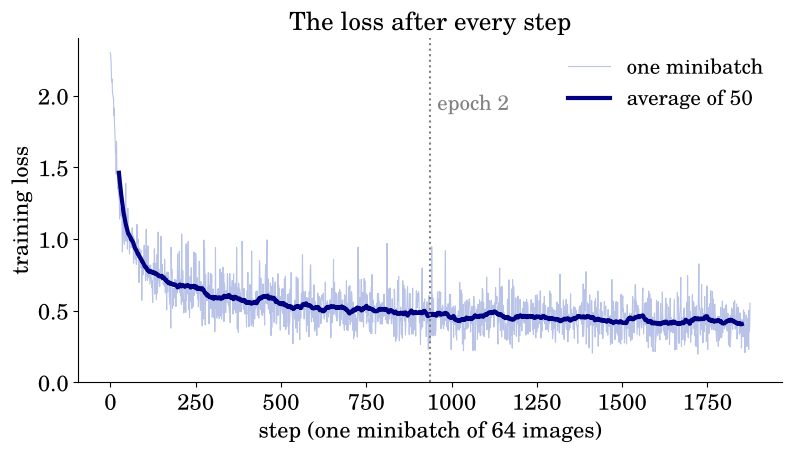

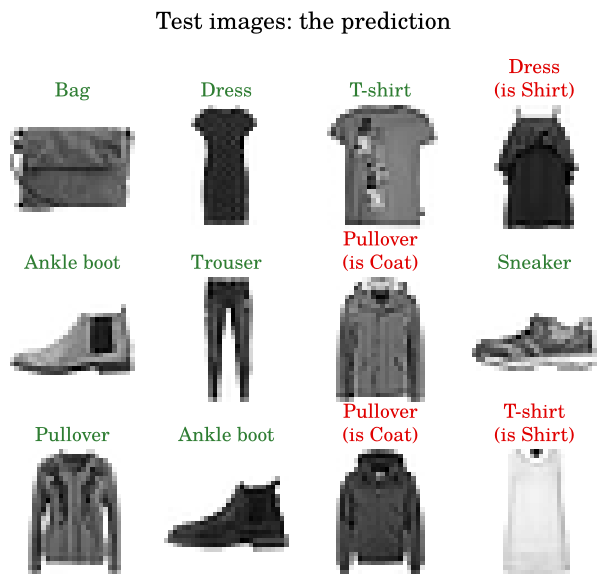

In [12]:
fig, ax = plt.subplots(figsize=(8.2, 4.8))
L = np.array(losses)
smooth = np.convolve(L, np.ones(50) / 50, mode='valid')
ax.plot(L, color='#B9C3E8', lw=0.8, label='one minibatch')
ax.plot(np.arange(len(smooth)) + 25, smooth, color=NAVY, lw=3, label='average of 50')
ax.axvline(len(train_loader), color=GREY, ls=':', lw=1.5); ax.text(len(train_loader) + 20, 1.9, 'epoch 2', color=GREY, fontsize=15)
ax.set_xlabel('step (one minibatch of 64 images)'); ax.set_ylabel('training loss'); ax.set_ylim(0, 2.4)
ax.set_title('The loss after every step', fontsize=18); ax.legend(frameon=False, fontsize=15)
plt.tight_layout(); fig.savefig(FIG / 'training_loss.png', dpi=200, bbox_inches='tight'); plt.show()

xt, yt = next(iter(DataLoader(test_set, batch_size=12, shuffle=True, generator=torch.Generator().manual_seed(3))))
model.eval()
with torch.no_grad():
    pt = model(xt.to(device)).argmax(1).cpu()
model.train()
fig, axes = plt.subplots(3, 4, figsize=(6.4, 6.0))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(xt[k, 0], cmap='gray_r'); ax.axis('off')
    ok = bool(pt[k] == yt[k])
    ax.set_title(CLASSES[pt[k]].split('/')[0] + ('' if ok else f'\n(is {CLASSES[yt[k]].split("/")[0]})'),
                 fontsize=14, color=(GREEN if ok else RED))
plt.suptitle('Test images: the prediction', fontsize=17)
plt.tight_layout(h_pad=1.2)
fig.savefig(FIG / 'predictions.png', dpi=200, bbox_inches='tight'); plt.show()

## 5. Debug the AI

We asked an AI assistant for a small network that predicts house prices from four features (size in m², bedrooms, floors, age), with prices in units of $100,000.
The code below **runs without an error**. It has three bugs. Find them before running the next cells.

In [13]:
# 500 houses, synthetic but realistic (same features as the table on Jan 18)
g = np.random.default_rng(0)
n = 500
size, beds, floors, age = g.uniform(100, 500, n), g.integers(1, 7, n), g.integers(1, 4, n), g.uniform(0, 80, n)
price = (50 + 0.8 * size + 12 * beds + 8 * floors - 1.0 * age + g.normal(0, 20, n)) / 100   # in $100k
features = torch.tensor(np.c_[size, beds, floors, age], dtype=torch.float32)
prices = torch.tensor(price, dtype=torch.float32)
print('features', tuple(features.shape), ' prices', tuple(prices.shape), f'  mean price {prices.mean():.2f}, std {prices.std():.2f}')

features (500, 4)  prices (500,)   mean price 3.18, std 0.98


In [14]:
# ---- the AI's code, exactly as on the slide ----
torch.manual_seed(0)
X = features                                    # size, bedrooms, floors, age
y = prices                                      # price in $100k
model = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 1))
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
for epoch in range(500):
    pred = model(X)
    loss = loss_fn(pred, y)
    loss.backward()
    optimizer.step()
print('final loss:', loss.item())

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([500])) that is different to the input size (torch.Size([500, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


final loss: 146850768.0


**The three bugs.**
1. `X` is not scaled: size is in the hundreds, bedrooms in single digits. The first steps are enormous and the ReLU units die.
2. No `optimizer.zero_grad()`: gradients from every step pile up, so the steps keep growing.
3. `pred` has shape `(500, 1)` and `y` has shape `(500,)`: `MSELoss` broadcasts to a `500 × 500` table (PyTorch warns, but only once). The model can only learn the average price.

Below, each bug is run alone (the other two fixed), next to the corrected code.

In [15]:
def train_houses(scale=True, zero_grad=True, fix_shape=True, epochs=500):
    torch.manual_seed(0)
    X = (features - features.mean(0)) / features.std(0) if scale else features
    y = prices.unsqueeze(1) if fix_shape else prices          # (500, 1) to match pred
    model = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 1))
    loss_fn = nn.MSELoss(); optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
    hist = []
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for epoch in range(epochs):
            pred = model(X); loss = loss_fn(pred, y)
            if zero_grad: optimizer.zero_grad()
            loss.backward(); optimizer.step(); hist.append(loss.item())
    with torch.no_grad():
        p = model(X).squeeze(1)
    rmse = ((p - prices) ** 2).mean().sqrt().item()
    return np.array(hist), rmse, p.std().item()

runs = {'corrected code': {}, 'bug 1 only: inputs not scaled': dict(scale=False),
        'bug 2 only: no zero_grad()': dict(zero_grad=False), 'bug 3 only: shapes (500,1) vs (500,)': dict(fix_shape=False)}
results = {k: train_houses(**v) for k, v in runs.items()}
print(f'always guessing the average price: RMSE {prices.std(unbiased=False):.2f}  (${prices.std(unbiased=False) * 100:.0f}k)')
for k, (h, rmse, spread) in results.items():
    print(f'{k:38s} final loss {h[-1]:9.3g}   RMSE {rmse:.2f} (${rmse * 100:.0f}k)   spread of predictions {spread:.2f}')

always guessing the average price: RMSE 0.98  ($98k)
corrected code                         final loss    0.0508   RMSE 0.23 ($23k)   spread of predictions 0.96
bug 1 only: inputs not scaled          final loss     0.966   RMSE 0.98 ($98k)   spread of predictions 0.00
bug 2 only: no zero_grad()             final loss     0.735   RMSE 0.58 ($58k)   spread of predictions 0.71
bug 3 only: shapes (500,1) vs (500,)   final loss     0.973   RMSE 0.98 ($98k)   spread of predictions 0.11


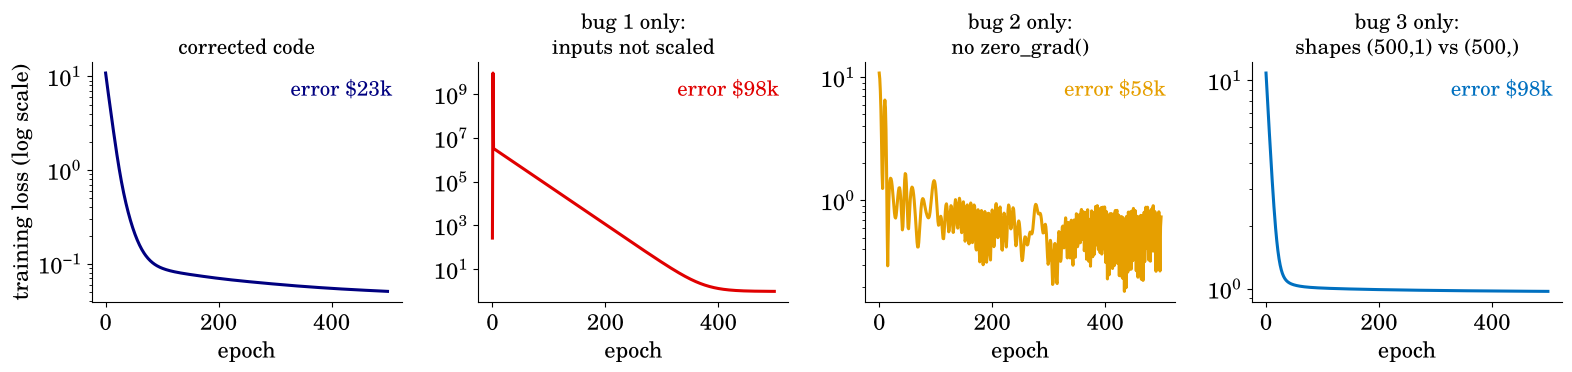

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.0), sharex=True)
cols = [NAVY, RED, ORANGE, BLUE]
for ax, (k, (h, rmse, spread)), c in zip(axes, results.items(), cols):
    ax.semilogy(h, color=c, lw=2.2)
    ax.set_title(k.replace(': ', ':\n'), fontsize=15)
    ax.text(0.97, 0.93, f'error ${rmse * 100:.0f}k', transform=ax.transAxes, ha='right', va='top', fontsize=15, color=c)
    ax.set_xlabel('epoch')
axes[0].set_ylabel('training loss (log scale)')
plt.tight_layout(); fig.savefig(FIG / 'bugs.png', dpi=200, bbox_inches='tight'); plt.show()

**What to notice.** Bug 1 explodes and then flat-lines: the network is dead and predicts one number. Bug 2 never settles. Bug 3 is the dangerous one: the loss goes down smoothly,
nothing crashes, and the model is useless (its error equals always guessing the average). The corrected code is off by about $23k, close to the $20k noise built into the data.

## 6. Exercises (after class)

1. **Shapes.** Change the first layer to `nn.Linear(28 * 28, 64)` and predict every shape in section 1 before running it.
2. **Nudge test.** Pick a weight of the *trained* Fashion-MNIST model and compare autograd with the nudge test. Why is the gradient small now?
3. **A fourth bug.** Put `nn.Softmax(dim=1)` at the end of the Fashion-MNIST model and train again. `nn.CrossEntropyLoss` already applies softmax: what happens to training?
4. **Use your AI.** Ask an AI assistant to write a training loop for the house prices, then check it against the checklist on slide 22. Did it make any of today's mistakes?